<a href="https://colab.research.google.com/github/gayatrishekharcs/AI_LAB/blob/main/Week9_1BM24CS103_FOL_RESOLUTION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Enter the person's name to prove: Alice
Enter Bob's name: Bob

========== FOL USING RESOLUTION ==========

1. FOL STATEMENTS:
C1: ~Science(x) OR Physics(x) OR Mathematics(x)
C2: ~Mathematics(x) OR Statistics(x)
C3: Science(Alice)
C4: Physics(Bob)
C5: ~Statistics(x) OR DataAnalysis(x)

2. CNF CLAUSES:
C1 : ~S(x) OR P(x) OR M(x)
C2 : ~M(x) OR T(x)
C3 : S(Alice)
C4 : P(Bob)
C5 : ~T(x) OR D(x)
C6 : ~D(Alice)

C6 is the negated goal.

3. RESOLUTION STEPS:
C1 + C3 => C7: P(Alice) OR M(Alice)
C2 + C7 => C8: P(Alice) OR T(Alice)
C5 + C8 => C9: P(Alice) OR D(Alice)
C6 + C9 => C10: P(Alice)

4. FINAL RESULT:
P(Alice) => Alice likes Physics.

Empty clause {} is NOT derived.
Therefore, the given premises are insufficient
to prove that Alice likes Data Analysis.


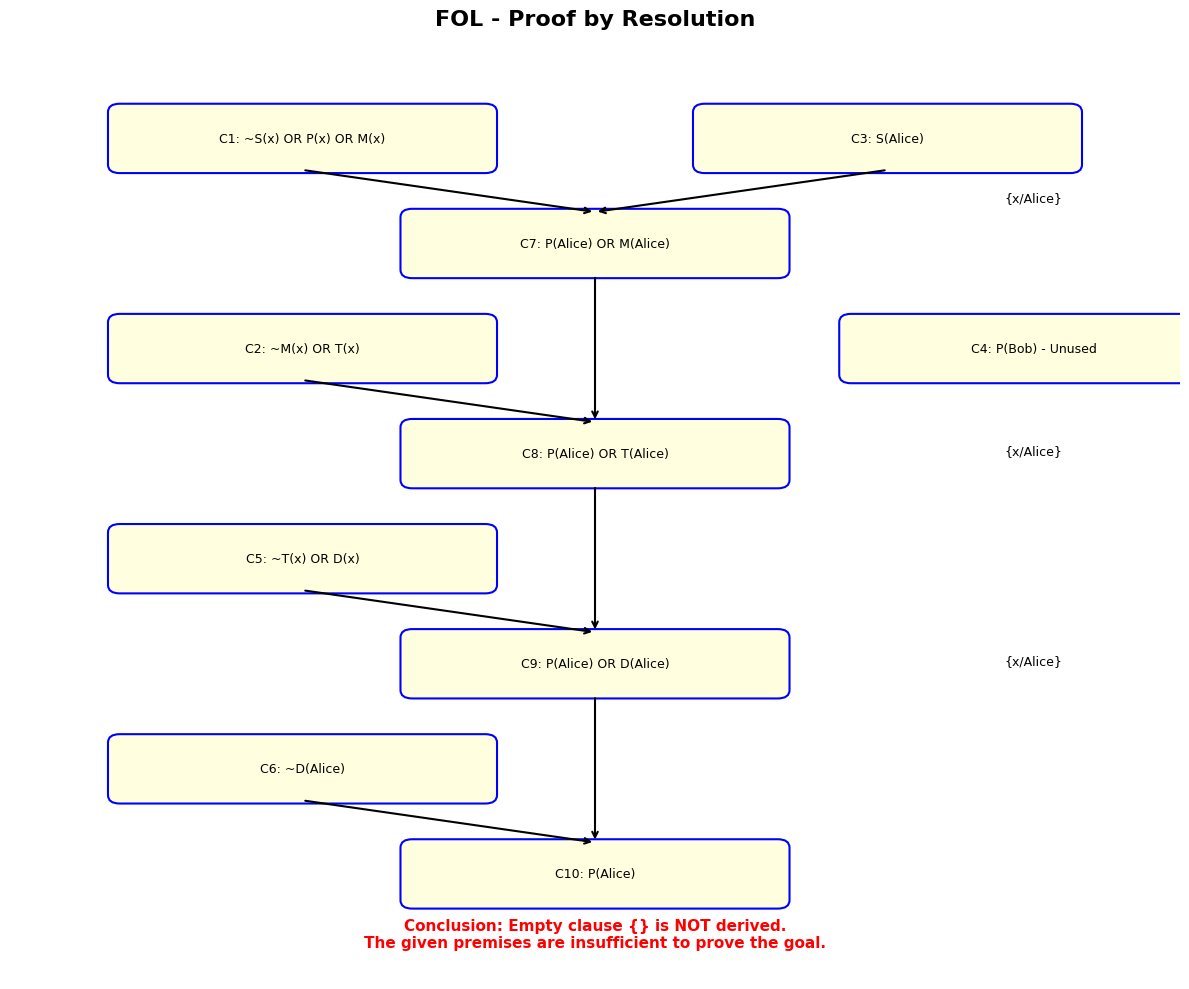


Resolution graph saved as resolution_graph.png


In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# -----------------------------------
# 1. USER INPUT
# -----------------------------------

alice = input("Enter the person's name to prove: ").strip() or "Alice"
bob = input("Enter Bob's name: ").strip() or "Bob"

a = alice.capitalize()
b = bob.capitalize()

print("\n========== FOL USING RESOLUTION ==========")

# -----------------------------------
# 2. GIVEN FOL STATEMENTS
# -----------------------------------

print("\n1. FOL STATEMENTS:")

print(f"C1: ~Science(x) OR Physics(x) OR Mathematics(x)")
print(f"C2: ~Mathematics(x) OR Statistics(x)")
print(f"C3: Science({a})")
print(f"C4: Physics({b})")
print(f"C5: ~Statistics(x) OR DataAnalysis(x)")

# -----------------------------------
# 3. CNF CLAUSES
# -----------------------------------

print("\n2. CNF CLAUSES:")

C1 = f"~S(x) OR P(x) OR M(x)"
C2 = f"~M(x) OR T(x)"
C3 = f"S({a})"
C4 = f"P({b})"
C5 = f"~T(x) OR D(x)"
C6 = f"~D({a})"

clauses = {
    "C1": C1,
    "C2": C2,
    "C3": C3,
    "C4": C4,
    "C5": C5,
    "C6": C6
}

for key, value in clauses.items():
    print(key, ":", value)

print("\nC6 is the negated goal.")

# -----------------------------------
# 4. APPLY RESOLUTION
# -----------------------------------

print("\n3. RESOLUTION STEPS:")

C7 = f"P({a}) OR M({a})"
print("C1 + C3 => C7:", C7)

C8 = f"P({a}) OR T({a})"
print("C2 + C7 => C8:", C8)

C9 = f"P({a}) OR D({a})"
print("C5 + C8 => C9:", C9)

C10 = f"P({a})"
print("C6 + C9 => C10:", C10)

print("\n4. FINAL RESULT:")
print(C10, "=>", a, "likes Physics.")

print("\nEmpty clause {} is NOT derived.")
print("Therefore, the given premises are insufficient")
print(f"to prove that {a} likes Data Analysis.")

# -----------------------------------
# 5. DRAW RESOLUTION GRAPH
# -----------------------------------

fig, ax = plt.subplots(figsize=(12, 10))
ax.set_xlim(-4, 4)
ax.set_ylim(-3, 6)
ax.axis("off")

nodes = {
    "C1": (-2, 5, C1),
    "C3": (2, 5, C3),
    "C7": (0, 4, C7),
    "C2": (-2, 3, C2),
    "C8": (0, 2, C8),
    "C5": (-2, 1, C5),
    "C9": (0, 0, C9),
    "C6": (-2, -1, C6),
    "C10": (0, -2, C10),
    "C4": (3, 3, f"P({b}) - Unused")
}

# Draw clause boxes
for name, (x, y, label) in nodes.items():

    box = FancyBboxPatch(
        (x - 1.25, y - 0.25),
        2.5, 0.5,
        boxstyle="round,pad=0.08",
        edgecolor="blue",
        facecolor="lightyellow",
        linewidth=1.5
    )

    ax.add_patch(box)

    ax.text(
        x, y,
        f"{name}: {label}",
        ha="center",
        va="center",
        fontsize=9
    )

# Draw resolution connections
edges = [
    ("C1", "C7", "S"),
    ("C3", "C7", "S"),
    ("C2", "C8", "M"),
    ("C7", "C8", "M"),
    ("C5", "C9", "T"),
    ("C8", "C9", "T"),
    ("C6", "C10", "D"),
    ("C9", "C10", "D")
]

for source, target, label in edges:

    x1, y1, _ = nodes[source]
    x2, y2, _ = nodes[target]

    ax.annotate(
        "",
        xy=(x2, y2 + 0.3),
        xytext=(x1, y1 - 0.3),
        arrowprops=dict(
            arrowstyle="->",
            color="black",
            lw=1.5
        )
    )

# Add substitutions
ax.text(2.8, 4.4, "{x/Alice}", fontsize=9)
ax.text(2.8, 2.0, "{x/Alice}", fontsize=9)
ax.text(2.8, 0.0, "{x/Alice}", fontsize=9)

ax.text(
    0, -2.7,
    "Conclusion: Empty clause {} is NOT derived.\n"
    "The given premises are insufficient to prove the goal.",
    ha="center",
    fontsize=11,
    color="red",
    fontweight="bold"
)

plt.title(
    "FOL - Proof by Resolution",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig("resolution_graph.png", dpi=200)
plt.show()

print("\nResolution graph saved as resolution_graph.png")